# Lab 4 — Notebook 3: Model Development & Slicing

**Author:** Kshitij Maurya

**Goal:** train sentiment classifiers on the *weak* labels, then test them on reviews with *true* labels — overall and on slices of the data.

```
Notebook 1: Weak Labeling -> Notebook 2: Augmentation -> [Notebook 3: Model Development]
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LAB_ROOT = Path.cwd().parent          # notebooks/ -> Lab4/
sys.path.insert(0, str(LAB_ROOT))

from src.config import load_config, lab_path
from src.data_validator import DataValidator
from src import utils

cfg = load_config()
FIG_DIR = lab_path(cfg["model"]["figures_dir"])
POS, NEG, ABSTAIN = cfg["labeling"]["positive"], cfg["labeling"]["negative"], cfg["labeling"]["abstain"]
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

import joblib
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC

SEED = cfg["model"]["random_state"]

### Step 1 — Load the training and test data
* **train**: augmented reviews with *weak* labels (Notebooks 1–2)
* **test**: held-out reviews with *true* labels (never seen by the rules or the model)

In [2]:
train = utils.load_reviews(lab_path(cfg["data"]["augmented"]))
test = utils.load_reviews(lab_path(cfg["data"]["test_gold"]))

for d in (train, test):
    d["n_words"] = d["text"].apply(utils.word_count)
    d["n_exclaims"] = d["text"].str.count("!")

X_train, y_train = train[["text", "n_words", "n_exclaims"]], train["weak_label"]
X_test, y_test = test[["text", "n_words", "n_exclaims"]], test["gold"]
print(f"Train: {len(train):,} (weak labels) | Test: {len(test):,} (true labels)")

Loaded imdb_augmented.csv: 3,490 rows, 4 columns
Loaded imdb_test_gold.csv: 1,600 rows, 2 columns
Train: 3,490 (weak labels) | Test: 1,600 (true labels)


### Step 2 — Build the features and models
* **TF-IDF** on the review text (single words and two-word phrases)
* **numeric**: word count and number of `!`, scaled to 0–1

Three models are compared: Logistic Regression, Multinomial Naive Bayes, and a Linear SVM (calibrated so it outputs probabilities).

In [3]:
def make_pipeline(classifier):
    features = ColumnTransformer([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                  max_features=cfg["model"]["tfidf_max_features"]), "text"),
        ("numeric", MinMaxScaler(), ["n_words", "n_exclaims"]),
    ])
    return Pipeline([("features", features), ("model", classifier)])

models = {
    "LogisticRegression": make_pipeline(LogisticRegression(max_iter=2000)),
    "NaiveBayes": make_pipeline(MultinomialNB()),
    "LinearSVM": make_pipeline(CalibratedClassifierCV(LinearSVC(random_state=SEED), cv=3)),
}

### Step 3 — Compare models with 5-fold cross-validation
Cross-validation uses only the training data, so the test set stays untouched until the end. The best model is chosen by mean ROC-AUC.

In [4]:
cv = StratifiedKFold(n_splits=cfg["model"]["cv_folds"], shuffle=True, random_state=SEED)
cv_scores = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_scores[name] = scores
    print(f"{name:20} ROC-AUC = {scores.mean():.4f} ± {scores.std():.4f}")

best_name = max(cv_scores, key=lambda n: cv_scores[n].mean())
best_model = models[best_name]
print(f"\nBest model: {best_name}")

LogisticRegression   ROC-AUC = 0.9652 ± 0.0049


NaiveBayes           ROC-AUC = 0.9564 ± 0.0065


LinearSVM            ROC-AUC = 0.9738 ± 0.0050

Best model: LinearSVM


### Step 4 — Pick a decision threshold
Instead of always using 0.5, we choose the probability cut-off with the best F1 score on **cross-validated training predictions** (again without looking at the test set).

In [5]:
cv_prob = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.arange(0.30, 0.71, 0.05)
f1s = [f1_score(y_train, (cv_prob >= t).astype(int)) for t in thresholds]
threshold = float(thresholds[int(np.argmax(f1s))])
print(f"Chosen threshold: {threshold:.2f} (CV F1 = {max(f1s):.4f})")

Chosen threshold: 0.50 (CV F1 = 0.9209)


### Step 5 — Train the best model and evaluate on the true labels
This is the honest score: how well a model trained only on rule-made labels predicts real sentiment.

              precision    recall  f1-score   support

    negative      0.822     0.858     0.839       800
    positive      0.851     0.814     0.832       800

    accuracy                          0.836      1600
   macro avg      0.836     0.836     0.836      1600
weighted avg      0.836     0.836     0.836      1600

ROC-AUC: 0.925


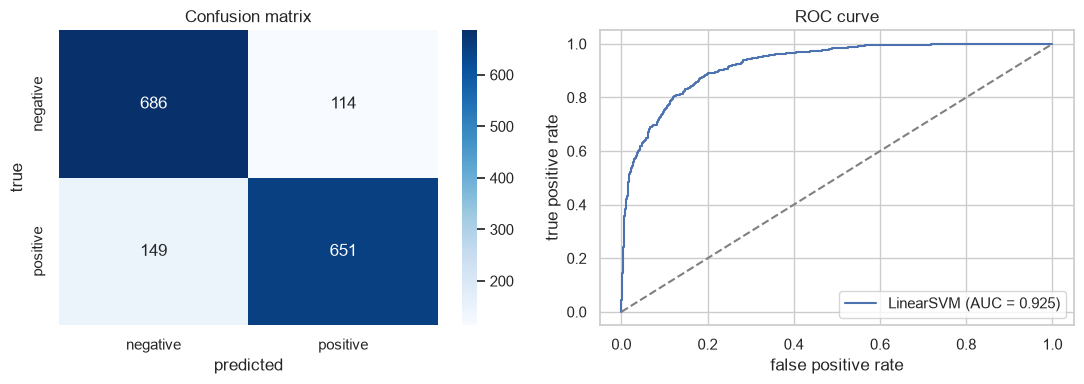

In [6]:
best_model.fit(X_train, y_train)
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

print(classification_report(y_test, test_pred, target_names=["negative", "positive"], digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title("Confusion matrix")
fpr, tpr, _ = roc_curve(y_test, test_prob)
axes[1].plot(fpr, tpr, label=f"{best_name} (AUC = {roc_auc_score(y_test, test_prob):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout()
utils.save_fig(fig, FIG_DIR / "03_test_evaluation.png")
fig

### Step 6 — Evaluate on data slices
A single accuracy number can hide weak spots. We check the model on groups of reviews that might be harder:

| Slice | Definition |
|-------|------------|
| `short_reviews` | fewer than 100 words |
| `long_reviews` | more than 400 words |
| `mentions_score` | contains a score like *7/10* |
| `many_negations` | 4 or more *not / n't / never* |
| `but_in_ending` | the last sentence contains *but / however* (mixed opinion) |

In [7]:
last_sentence = test["text"].str.split(r"[.!?]\s+").str[-1]
slices = {
    "all": pd.Series(True, index=test.index),
    "short_reviews": test["n_words"] < 100,
    "long_reviews": test["n_words"] > 400,
    "mentions_score": test["text"].apply(utils.extract_rating).notna(),
    "many_negations": test["text"].str.count(r"\bnot\b|n't\b|\bnever\b") >= 4,
    "but_in_ending": last_sentence.str.contains(r"\b(?:but|however)\b"),
}

rows = []
for name, mask in slices.items():
    rows.append({"slice": name, "n": int(mask.sum()),
                 "accuracy": accuracy_score(y_test[mask], test_pred[mask]),
                 "f1": f1_score(y_test[mask], test_pred[mask])})
slice_df = pd.DataFrame(rows).set_index("slice").round(3)
slice_df

,n,accuracy,f1
slice,,,
all,1600,0.836,0.832
short_reviews,188,0.819,0.844
long_reviews,220,0.845,0.833
mentions_score,144,0.861,0.882
many_negations,456,0.840,0.767
but_in_ending,230,0.826,0.813


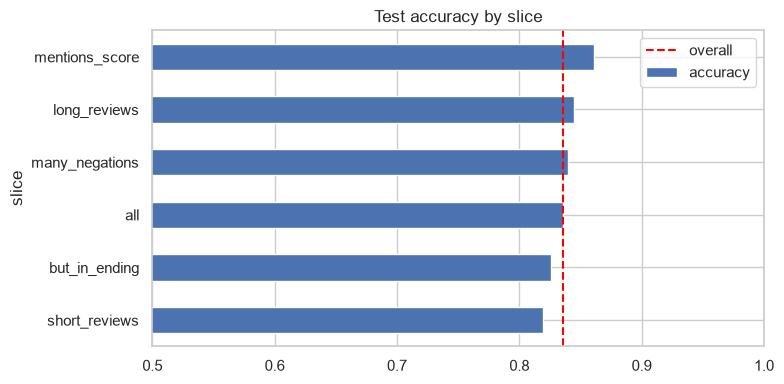

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
slice_df["accuracy"].sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.axvline(slice_df.loc["all", "accuracy"], color="red", linestyle="--", label="overall")
ax.set_xlim(0.5, 1); ax.set_title("Test accuracy by slice"); ax.legend()
plt.tight_layout()
utils.save_fig(fig, FIG_DIR / "03_slices.png")
fig

### Step 7 — Which words drive the predictions?
We look at the Logistic Regression weights: large positive weights push towards *positive*, large negative weights towards *negative*.

In [9]:
logreg = models["LogisticRegression"]
if logreg is not best_model:
    logreg.fit(X_train, y_train)

names = logreg.named_steps["features"].get_feature_names_out()
weights = pd.Series(logreg.named_steps["model"].coef_[0], index=names)
weights = weights[weights.index.str.startswith("tfidf__")].rename(lambda s: s.replace("tfidf__", ""))

pd.DataFrame({
    "most positive": weights.nlargest(15).index,
    "weight (+)": weights.nlargest(15).values.round(2),
    "most negative": weights.nsmallest(15).index,
    "weight (-)": weights.nsmallest(15).values.round(2),
})

,most positive,weight (+),most negative,weight (-)
0,excellent,4.90,worst,-4.60
1,wonderful,4.03,boring,-4.29
2,brilliant,3.59,bad,-3.88
3,masterpiece,2.51,the worst,-3.76
4,great,2.30,terrible,-3.51
5,superb,2.22,awful,-3.41
6,an excellent,1.85,horrible,-2.78
7,must see,1.85,waste,-2.61
8,love,1.71,waste of,-1.90
9,10,1.60,not,-1.88


### Step 8 — Save the model and the test predictions

In [10]:
model_path = lab_path(cfg["model"]["model_path"])
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": best_model, "model_name": best_name, "threshold": threshold}, model_path)
print("Saved model ->", model_path.relative_to(LAB_ROOT))

predictions = test.assign(prob_positive=test_prob.round(4), predicted=test_pred)[["text", "gold", "predicted", "prob_positive"]]
utils.save_csv(predictions, lab_path(cfg["model"]["predictions_path"]))

Saved model -> outputs/best_model.pkl
Saved 1,600 rows -> predictions_test.csv


### Step 9 — Try the saved model on new reviews

In [11]:
saved = joblib.load(model_path)

def predict_sentiment(reviews):
    texts = pd.Series(reviews).apply(utils.clean_review)
    X = pd.DataFrame({"text": texts, "n_words": texts.apply(utils.word_count), "n_exclaims": texts.str.count("!")})
    prob = saved["model"].predict_proba(X)[:, 1]
    return pd.DataFrame({"review": reviews, "prob_positive": prob.round(3),
                         "prediction": np.where(prob >= saved["threshold"], "positive", "negative")})

predict_sentiment([
    "One of the best films I have seen this year. The cast is fantastic!",
    "Two hours of my life I will never get back. Dull and predictable.",
    "The story was not bad, but the ending felt rushed.",
])

,review,prob_positive,prediction
0,One of the best films I have seen this year. The cast is fantastic!,0.963,positive
1,Two hours of my life I will never get back. Dull and predictable.,0.337,negative
2,"The story was not bad, but the ending felt rushed.",0.055,negative


### Step 10 — Summary

In [12]:
summary = pd.DataFrame({
    "metric": ["best model", "CV ROC-AUC (weak labels)", "threshold",
               "test accuracy (true labels)", "test ROC-AUC (true labels)", "weakest slice"],
    "value": [best_name, f"{cv_scores[best_name].mean():.3f}", f"{threshold:.2f}",
              f"{accuracy_score(y_test, test_pred):.3f}", f"{roc_auc_score(y_test, test_prob):.3f}",
              f"{slice_df['accuracy'].idxmin()} ({slice_df['accuracy'].min():.3f})"],
})
summary

,metric,value
0,best model,LinearSVM
1,CV ROC-AUC (weak labels),0.974
2,threshold,0.50
3,test accuracy (true labels),0.836
4,test ROC-AUC (true labels),0.925
5,weakest slice,short_reviews (0.819)
